# Part E — Literature scatter of HZ class and rocky flag across published solutions

*Project 2 extension (Part 04, 23 Nov 2026). Self-contained: does not need the variables of `Exoplanet_P1_P2.ipynb`, only the file `P2_rocky_HZ_ranked_2026-11-22.csv` in the same folder.*

**Question.** For each candidate rocky-HZ planet, how often do the habitable-zone class and the rocky flag change when a different published solution (one row of the Planetary Systems `ps` table per reference) is used instead of the composite table (`pscomppars`)?

**Rules (same as Parts B–C).**
- S = L/a² (`st_lum` is log10 L/L☉). Fallbacks, flagged in `S_src`: L = R★²(T_eff/5772)⁴ if `st_lum` is blank; a from Kepler's third law (P, M★) if `pl_orbsmax` is blank; archive `pl_insol` as last resort.
- HZ limits: Kopparapu et al. (2014), 1 M⊕; conservative = runaway → maximum greenhouse; optimistic = recent Venus → early Mars; valid 2600–7200 K.
- Rocky = R ≤ 1.6 R⊕ (Rogers 2015). In `ps` most RV rows have **no radius**; for those with M ≤ 3 M⊕ a radius is estimated as R = M^0.279 (Chen & Kipping 2017, same rule as Part C) and flagged `R_src = "estimated (C&K17)"`. Statistics are reported both with and without estimated radii.

## E1. Settings and download of the `ps` table (one row per planet per reference)

In [37]:
import os, io, ssl, datetime, urllib.request, urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TODAY = datetime.date.today().isoformat()
P2_TABLE = "P2_rocky_HZ_ranked_2026-11-22.csv"     # 32 rocky-HZ planets from pscomppars
DATA_DATE = "2026-11-23"                             # frozen download used for note 2
PS_FILE  = "ps_" + DATA_DATE + ".csv"

try:
    import certifi
    SSL_CTX = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    SSL_CTX = ssl.create_default_context()

PS_COLS = ["pl_name", "hostname", "default_flag", "soltype", "pl_controv_flag",
           "pl_refname", "disc_refname", "pl_pubdate", "discoverymethod", "tran_flag", "rv_flag",
           "pl_orbper", "pl_orbsmax", "pl_orbsmaxerr1", "pl_orbsmaxerr2", "pl_orbeccen",
           "pl_rade", "pl_radeerr1", "pl_radeerr2", "pl_bmasse", "pl_bmassprov",
           "pl_insol", "pl_insolerr1", "pl_insolerr2",
           "st_teff", "st_tefferr1", "st_tefferr2", "st_rad", "st_mass",
           "st_lum", "st_lumerr1", "st_lumerr2", "st_refname"]

def tap_csv(adql):
    url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
           + urllib.parse.quote(adql) + "&format=csv")
    with urllib.request.urlopen(url, context=SSL_CTX, timeout=300) as r:
        return pd.read_csv(io.BytesIO(r.read()))

if os.path.exists(PS_FILE):
    ps = pd.read_csv(PS_FILE)
    print("Loaded saved file", PS_FILE)
else:
    ps = tap_csv("select " + ", ".join(PS_COLS) + " from ps")
    ps.to_csv(PS_FILE, index=False)
    print("Downloaded and saved", PS_FILE)

print("Rows (solutions):", len(ps), "| planets:", ps["pl_name"].nunique())
print("Default rows:", int((ps["default_flag"] == 1).sum()))
print(ps["soltype"].value_counts())

Loaded saved file ps_2026-11-23.csv
Rows (solutions): 40428 | planets: 6473
Default rows: 6473
Published Confirmed                               20788
Kepler Project Candidate (q1_q17_dr25_sup_koi)     2736
Kepler Project Candidate (q1_q16_koi)              2723
Kepler Project Candidate (q1_q17_dr25_koi)         2719
Kepler Project Candidate (q1_q17_dr24_koi)         2702
Kepler Project Candidate (q1_q12_koi)              2681
Kepler Project Candidate (q1_q8_koi)               2308
Published Candidate                                2198
TESS Project Candidate                             1573
Name: soltype, dtype: int64


## E2. Per-solution S, T_eff, R and HZ class

In [38]:
# Kopparapu et al. 2014, 1 Earth mass: S_eff_sun, a, b, c, d
KOP = {"recent_venus": (1.776, 2.136e-4, 2.533e-8, -1.332e-11, -3.097e-15),
       "runaway":      (1.107, 1.332e-4, 1.580e-8, -8.308e-12, -1.931e-15),
       "max_gh":       (0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16),
       "early_mars":   (0.320, 5.547e-5, 1.526e-9, -2.874e-12, -5.011e-16)}

def seff(teff, key):
    s0, a, b, c, d = KOP[key]
    t = np.asarray(teff, dtype=float) - 5780.0
    return s0 + a*t + b*t**2 + c*t**3 + d*t**4

# TRAPPIST-1 (T_eff ~2566 K) lies just below the 2600 K validity limit. Set TEFF_CLIP to match Part B:
# True = evaluate the limits at the nearest valid T_eff (row flagged in 'Teff_clipped'); False = leave unclassified.
TEFF_CLIP = True

def hz_class(S, teff):
    """Returns 'conservative', 'optimistic', 'out', or NaN (no data, or T_eff out of range when TEFF_CLIP=False)."""
    S = np.asarray(S, dtype=float); T = np.asarray(teff, dtype=float)
    if TEFF_CLIP:
        T = np.clip(T, 2600, 7200)
    out = np.full(S.shape, np.nan, dtype=object)
    ok = np.isfinite(S) & np.isfinite(T) & (T >= 2600) & (T <= 7200)
    cons = ok & (S <= seff(T, "runaway")) & (S >= seff(T, "max_gh"))
    opt  = ok & ~cons & (S <= seff(T, "recent_venus")) & (S >= seff(T, "early_mars"))
    out[ok] = "out"; out[opt] = "optimistic"; out[cons] = "conservative"
    return out

MASS_MAX_NO_RADIUS = 3.0   # same rule as Part C

def ck17_radius(m):
    """Part C rule: Chen & Kipping (2017) Terran branch R = M^0.279, only for M <= 3 M_E (else no estimate)."""
    m = np.asarray(m, dtype=float)
    return np.where(m <= MASS_MAX_NO_RADIUS, m**0.279, np.nan)

# Solution types: the ps table also holds pipeline rows (Kepler KOI tables, TESS Project Candidate/ExoFOP)
# and "Published Candidate" rows for planets that were confirmed later. Main analysis = peer-reviewed
# solutions of confirmed planets; set USE_ALL_SOLTYPES = True for the sensitivity run.
USE_ALL_SOLTYPES = False
print(ps["soltype"].value_counts())
d = ps.copy() if USE_ALL_SOLTYPES else ps[ps["soltype"] == "Published Confirmed"].copy()
print("Solutions used:", len(d), "| planets:", d["pl_name"].nunique())

# Luminosity: log10 L from st_lum, else from R* and T_eff
L = 10**d["st_lum"]
L_sb = d["st_rad"]**2 * (d["st_teff"] / 5772.0)**4
L_src = np.where(np.isfinite(L), "st_lum", np.where(np.isfinite(L_sb), "R*,Teff", ""))
L = L.where(np.isfinite(L), L_sb)

# Semi-major axis: pl_orbsmax, else Kepler III from P (days) and M* (Msun)
a_k3 = (d["st_mass"] * (d["pl_orbper"] / 365.25)**2)**(1.0/3.0)
a_src = np.where(np.isfinite(d["pl_orbsmax"]), "a", np.where(np.isfinite(a_k3), "Kepler3", ""))
a = d["pl_orbsmax"].where(np.isfinite(d["pl_orbsmax"]), a_k3)

S_calc = L / a**2
d["S"] = S_calc.where(np.isfinite(S_calc), d["pl_insol"])
d["S_src"] = np.where(np.isfinite(S_calc),
                      pd.Series(L_src, index=d.index) + "/" + pd.Series(a_src, index=d.index),
                      np.where(np.isfinite(d["pl_insol"]), "pl_insol", ""))
d["HZ"] = hz_class(d["S"], d["st_teff"])
d["Teff_clipped"] = (d["st_teff"] < 2600) | (d["st_teff"] > 7200)
print("Solutions with T_eff outside 2600-7200 K:", int(d["Teff_clipped"].sum()),
      "(clipped)" if TEFF_CLIP else "(unclassified)")
d["inHZ"] = d["HZ"].isin(["conservative", "optimistic"]).where(d["HZ"].notna())

# Radius: measured if given, else C&K17 estimate from (minimum) mass
R_est = pd.Series(ck17_radius(d["pl_bmasse"]), index=d.index)
d["R_src"] = np.where(np.isfinite(d["pl_rade"]), "measured",
                      np.where(np.isfinite(R_est), "estimated (C&K17)", ""))
d["R"] = d["pl_rade"].where(np.isfinite(d["pl_rade"]), R_est)
d["rocky"] = (d["R"] <= 1.6).where(np.isfinite(d["R"]))
d["rocky_meas"] = (d["pl_rade"] <= 1.6).where(np.isfinite(d["pl_rade"]))
d["rockyHZ"] = (d["rocky"] == True) & (d["inHZ"] == True)

# Sanity check: an Earth twin around a Sun-like star
print("Earth twin:", hz_class([1.0], [5772])[0], "| Sun HZ (AU): %.2f-%.2f"
      % (1/np.sqrt(seff(5780, "runaway")), 1/np.sqrt(seff(5780, "max_gh"))))
print("Solutions with S:", int(d["S"].notna().sum()), "| with HZ class:", int(d["HZ"].notna().sum()),
      "| with radius (meas/est):", int((d["R_src"] == "measured").sum()), "/",
      int((d["R_src"] == "estimated (C&K17)").sum()))
print(pd.Series(d["S_src"]).value_counts().head(8))

Published Confirmed                               20788
Kepler Project Candidate (q1_q17_dr25_sup_koi)     2736
Kepler Project Candidate (q1_q16_koi)              2723
Kepler Project Candidate (q1_q17_dr25_koi)         2719
Kepler Project Candidate (q1_q17_dr24_koi)         2702
Kepler Project Candidate (q1_q12_koi)              2681
Kepler Project Candidate (q1_q8_koi)               2308
Published Candidate                                2198
TESS Project Candidate                             1573
Name: soltype, dtype: int64
Solutions used: 20788 | planets: 6473
Solutions with T_eff outside 2600-7200 K: 165 (clipped)
Earth twin: conservative | Sun HZ (AU): 0.95-1.68
Solutions with S: 16668 | with HZ class: 16589 | with radius (meas/est): 11206 / 198
st_lum/Kepler3     4563
                   4120
R*,Teff/Kepler3    4006
R*,Teff/a          3324
st_lum/a           2550
pl_insol           2225
Name: S_src, dtype: int64


## E3. Candidate set = 32 pscomppars rocky-HZ planets ∪ planets rocky-HZ in at least one `ps` solution

In [39]:
p2 = pd.read_csv(P2_TABLE)
comp_set = set(p2["pl_name"])
ps_set = set(d.loc[d["rockyHZ"], "pl_name"])
cands = sorted(comp_set | ps_set)

print("pscomppars rocky-HZ:", len(comp_set))
print("rocky-HZ in >= 1 ps solution:", len(ps_set))
print("Union (candidates):", len(cands))
print("In pscomppars list only:", sorted(comp_set - ps_set))
print("New from ps only:", len(ps_set - comp_set))
missing = sorted(comp_set - set(d["pl_name"]))
if missing:
    print("WARNING: names not found in ps (check spelling):", missing)

pscomppars rocky-HZ: 32
rocky-HZ in >= 1 ps solution: 42
Union (candidates): 43
In pscomppars list only: ['Kepler-1512 b']
New from ps only: 11


## E4. Per-planet stability of HZ class and rocky flag

In [40]:
def summarise(g):
    hz = g["HZ"].dropna(); rk = g["rocky"].dropna(); rkm = g["rocky_meas"].dropna()
    dflt = g[g["default_flag"] == 1]
    def frac(x): return float(np.mean(x.astype(float))) if len(x) else np.nan
    return pd.Series({
        "n_sol": len(g),
        "n_HZ_eval": len(hz),
        "n_R_eval": len(rk),
        "n_R_meas": len(rkm),
        "frac_inHZ": frac(hz.isin(["conservative", "optimistic"])),
        "frac_cons": frac(hz == "conservative"),
        "frac_rocky": frac(rk),
        "frac_rocky_meas": frac(rkm),
        "n_HZ_classes": hz.nunique(),          # 1 = stable; 2-3 = class changes between papers
        "HZ_changes": hz.nunique() > 1,
        "inout_changes": hz.isin(["conservative", "optimistic"]).nunique() > 1,
        "rocky_changes": rk.nunique() > 1,
        "rocky_meas_changes": rkm.nunique() > 1,
        "default_HZ": dflt["HZ"].iloc[0] if len(dflt) else np.nan,
        "default_rocky": dflt["rocky"].iloc[0] if len(dflt) else np.nan,
        "S_min": g["S"].min(), "S_max": g["S"].max(),
        "R_min": g["R"].min(), "R_max": g["R"].max(),
        "Teff_min": g["st_teff"].min(), "Teff_max": g["st_teff"].max(),
        "R_src_any_meas": (g["R_src"] == "measured").any(),
        "refs": "; ".join(g["pl_refname"].astype(str).str.replace(r"<[^>]+>", "", regex=True)
                          .str.strip().unique()[:6]),
    })

sub = d[d["pl_name"].isin(cands)]
summ = sub.groupby("pl_name").apply(summarise)
summ["in_pscomppars_list"] = summ.index.isin(comp_set)
summ["S_ratio"] = summ["S_max"] / summ["S_min"]
summ["R_ratio"] = summ["R_max"] / summ["R_min"]
summ = summ.sort_values(["in_pscomppars_list", "frac_inHZ"], ascending=[False, False])

TAG = DATA_DATE + ("_allsoltypes" if USE_ALL_SOLTYPES else "")
SUMM_FILE = "P2E_ps_scatter_summary_" + TAG + ".csv"
SOL_FILE  = "P2E_ps_solutions_candidates_" + TAG + ".csv"
summ.to_csv(SUMM_FILE)
sub.to_csv(SOL_FILE, index=False)
print("Saved", SUMM_FILE, "and", SOL_FILE)

Saved P2E_ps_scatter_summary_2026-11-23.csv and P2E_ps_solutions_candidates_2026-11-23.csv


## E5. Headline numbers for the note

In [41]:
def headline(s, label):
    multi = s[(s["n_HZ_eval"] >= 2)]
    multiR = s[(s["n_R_eval"] >= 2)]
    multiRm = s[(s["n_R_meas"] >= 2)]
    print("---", label, "---  planets:", len(s))
    print("  >=2 solutions with HZ class:", len(multi))
    print("    HZ class changes (cons/opt/out):", int(multi["HZ_changes"].sum()),
          "| in/out of HZ changes:", int(multi["inout_changes"].sum()))
    print("  >=2 solutions with radius (meas+est):", len(multiR),
          "| rocky flag changes:", int(multiR["rocky_changes"].sum()))
    print("  >=2 solutions with MEASURED radius:", len(multiRm),
          "| rocky flag changes:", int(multiRm["rocky_meas_changes"].sum()))
    either = s[(s["HZ_changes"]) | (s["rocky_changes"])]
    print("  Either label changes:", len(either), "of", len(s))
    print("  Median S_max/S_min (planets with >=2 S): %.2f" % s.loc[s["n_HZ_eval"] >= 2, "S_ratio"].median())
    print("  Rocky-HZ in only some solutions:", int(((s["frac_inHZ"] < 1) | (s["frac_rocky"] < 1)).sum()))

headline(summ, "All candidates")
headline(summ[summ["in_pscomppars_list"]], "The 32 pscomppars rocky-HZ planets")

# Default ps solution vs pscomppars: does the composite table agree with the archive's own default row?
c32 = summ[summ["in_pscomppars_list"]]
print("\nOf the 32, default ps row is rocky-HZ:",
      int(((c32["default_rocky"] == True) & c32["default_HZ"].isin(["conservative", "optimistic"])).sum()))

cols = ["n_sol", "n_HZ_eval", "frac_inHZ", "frac_cons", "n_R_meas", "frac_rocky", "frac_rocky_meas",
        "default_HZ", "S_min", "S_max", "R_min", "R_max", "in_pscomppars_list"]
unstable = summ[(summ["HZ_changes"]) | (summ["rocky_changes"])]
print("\nPlanets whose label depends on the paper used:")
print(unstable[cols].round(2).to_string())

--- All candidates ---  planets: 43
  >=2 solutions with HZ class: 30
    HZ class changes (cons/opt/out): 14 | in/out of HZ changes: 10
  >=2 solutions with radius (meas+est): 31 | rocky flag changes: 13
  >=2 solutions with MEASURED radius: 25 | rocky flag changes: 13
  Either label changes: 16 of 43
  Median S_max/S_min (planets with >=2 S): 1.39
  Rocky-HZ in only some solutions: 15
--- The 32 pscomppars rocky-HZ planets ---  planets: 32
  >=2 solutions with HZ class: 19
    HZ class changes (cons/opt/out): 4 | in/out of HZ changes: 2
  >=2 solutions with radius (meas+est): 20 | rocky flag changes: 3
  >=2 solutions with MEASURED radius: 14 | rocky flag changes: 3
  Either label changes: 5 of 32
  Median S_max/S_min (planets with >=2 S): 1.07
  Rocky-HZ in only some solutions: 4

Of the 32, default ps row is rocky-HZ: 29

Planets whose label depends on the paper used:
               n_sol  n_HZ_eval  frac_inHZ  frac_cons  n_R_meas  frac_rocky  frac_rocky_meas    default_HZ  S_min  

## E5b. Provenance mixing in pscomppars: do a, L* and T_eff come from different papers?


In [42]:
import re
FLUX_COLS = ["pl_orbsmax_reflink", "st_lum_reflink", "st_teff_reflink"]
PC_FILE = "pscomppars_reflinks_2026-11-24.csv"     # frozen download used for note 2
if os.path.exists(PC_FILE):
    pc = pd.read_csv(PC_FILE)
else:
    pc = tap_csv("select pl_name, " + ", ".join(FLUX_COLS) + " from pscomppars")
    pc.to_csv(PC_FILE, index=False)

def ref(x):
    if not isinstance(x, str):
        return None
    t = re.sub(r"<[^>]+>", "", x).strip()
    return t if t else None

pc = pc[pc["pl_name"].isin(comp_set)].copy()
for c in FLUX_COLS:
    pc[c] = pc[c].apply(ref)
pc["n_refs"] = pc[FLUX_COLS].apply(lambda r: len(set(v for v in r if v)), axis=1)
print("Of the 32 found:", len(pc))
print("a, L*, T_eff from >= 2 papers:", int((pc["n_refs"] >= 2).sum()),
      "| from 3 papers:", int((pc["n_refs"] >= 3).sum()))
print(pc.loc[pc["n_refs"] >= 2, ["pl_name"] + FLUX_COLS + ["n_refs"]].to_string())

Of the 32 found: 32
a, L*, T_eff from >= 2 papers: 8 | from 3 papers: 3
            pl_name          pl_orbsmax_reflink          st_lum_reflink         st_teff_reflink  n_refs
1117      TOI-700 d            Pass et al. 2026      Kokori et al. 2023     Gilbert et al. 2023       3
1185      TOI-700 e            Pass et al. 2026      Kokori et al. 2023     Gilbert et al. 2023       3
1389  Kepler-1512 b  Fulton &amp; Petigura 2018      Torres et al. 2017      Morton et al. 2016       3
2825   Kepler-296 e         Barclay et al. 2015        Mann et al. 2013     Barclay et al. 2015       2
3667        K2-72 e        Dressing et al. 2017                   TICv8    Dressing et al. 2017       2
3944  Kepler-1649 c       Q1-Q17 DR25 KOI Table  Vanderburg et al. 2020  Vanderburg et al. 2020       2
5696      TOI-715 b      Dransfield et al. 2024                   TICv8  Dransfield et al. 2024       2
6077  Kepler-1229 b          Torres et al. 2017      Torres et al. 2017      Morton et al. 2016 

## E6. Figure: HZ diagram with literature scatter (one marker per published solution, lines join solutions of the same planet)

Saved P2E_HZ_literature_scatter_2026-11-23.png


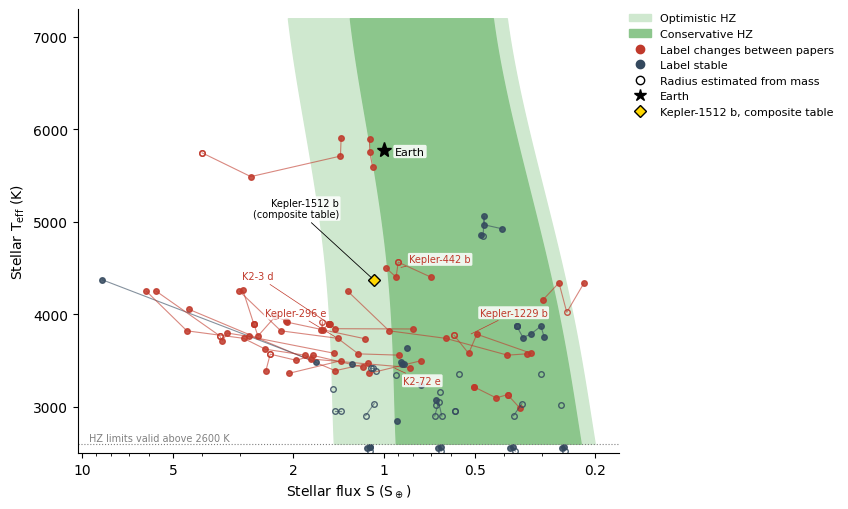

In [43]:
from matplotlib.ticker import NullFormatter

fig, ax = plt.subplots(figsize=(8.6, 5.2))
T = np.linspace(2600, 7200, 300)
ax.fill_betweenx(T, seff(T, "early_mars"), seff(T, "recent_venus"), color="#cfe8cf", label="Optimistic HZ")
ax.fill_betweenx(T, seff(T, "max_gh"), seff(T, "runaway"), color="#8cc68c", label="Conservative HZ")

# --- One marker per published solution; lines join solutions of the same planet ---
for name, g in sub.groupby("pl_name"):
    g = g.dropna(subset=["S", "st_teff"]).sort_values("S")
    if len(g) == 0:
        continue
    unstable_planet = bool(summ.loc[name, "HZ_changes"] or summ.loc[name, "rocky_changes"])
    col = "#c0392b" if unstable_planet else "#34495e"
    if len(g) > 1:
        ax.plot(g["S"], g["st_teff"], "-", color=col, lw=0.8, alpha=0.6)
    meas = g["R_src"] == "measured"
    ax.plot(g.loc[meas, "S"], g.loc[meas, "st_teff"], "o", ms=4, color=col, alpha=0.85)
    ax.plot(g.loc[~meas, "S"], g.loc[~meas, "st_teff"], "o", ms=4, mfc="none", mec=col, alpha=0.85)

# --- Polish: Earth, 2600 K limit, Kepler-1512 b composite point, labels ---
BOX = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)
ax.plot(1.0, 5772, "*", ms=11, color="k", zorder=6)
ax.annotate("Earth", xy=(1.0, 5772), xytext=(8, -3), textcoords="offset points",
            ha="left", fontsize=8, bbox=BOX, zorder=7)
ax.axhline(2600, color="grey", ls=":", lw=0.8)
ax.text(0.02, 2630, "HZ limits valid above 2600 K", transform=ax.get_yaxis_transform(),
        fontsize=7, color="grey")
# pscomppars value (22 Nov): S = 1.08, T_eff = 4372 K -- no published solution gives this
ax.plot(1.08, 4372, "D", ms=6, mfc="gold", mec="k", zorder=6)
ax.annotate("Kepler-1512 b\n(composite table)", xy=(1.08, 4372), xytext=(-25, 45),
            textcoords="offset points", ha="right", fontsize=7, bbox=BOX, zorder=7,
            arrowprops=dict(arrowstyle="-", lw=0.6))
LABELS = {"K2-72 e": (8, -12), "Kepler-1229 b": (8, 14), "Kepler-442 b": (8, 4),
          "Kepler-296 e": (-8, 16), "K2-3 d": (-40, 32)}
for name, off in LABELS.items():
    gl = sub[sub["pl_name"] == name].dropna(subset=["S", "st_teff"])
    if len(gl):
        ax.annotate(name, xy=(gl["S"].median(), gl["st_teff"].median()), xytext=off,
                    textcoords="offset points", ha="left" if off[0] > 0 else "right",
                    fontsize=7, color="#c0392b", bbox=BOX, zorder=7,
                    arrowprops=dict(arrowstyle="-", lw=0.5, color="#c0392b"))

# --- Legend entries ---
ax.plot([], [], "o", color="#c0392b", label="Label changes between papers")
ax.plot([], [], "o", color="#34495e", label="Label stable")
ax.plot([], [], "o", mfc="none", mec="k", label="Radius estimated from mass")
ax.plot([], [], "*", color="k", ms=9, label="Earth")
ax.plot([], [], "D", mfc="gold", mec="k", label="Kepler-1512 b, composite table")

# --- Axes and save ---
ax.set_xscale("log"); ax.invert_xaxis()
XT = [10, 5, 2, 1, 0.5, 0.2]
ax.set_xticks(XT); ax.set_xticklabels([str(x) for x in XT])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Stellar flux S (S$_\\oplus$)"); ax.set_ylabel("Stellar T$_{\\rm eff}$ (K)")
ax.set_ylim(2500, 7300)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), borderaxespad=0)
fig.tight_layout()
FIG_FILE = "P2E_HZ_literature_scatter_" + TAG + ".png"
fig.savefig(FIG_FILE, dpi=300, bbox_inches="tight")
print("Saved", FIG_FILE)
plt.show()

## E7. Checks before using the numbers
1. Read the `WARNING` line in E3: any of the 32 names not found in `ps` must be fixed (spelling) before counting.
2. Open `P2E_ps_solutions_candidates_<date>.csv` and hand-check 3 planets (good student task): recompute S = L/a² and the HZ class with a calculator for each solution.
3. Look at `S_src`: rows that used `Kepler3` or `pl_insol` are fallbacks; report how many.
4. Rows with `pl_controv_flag = 1` are controversial planets; report them separately rather than dropping them silently.